In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plot
import seaborn
import pathlib

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV

import time

path = pathlib.Path("C:\\Users\\PC\\Desktop\\ML_assignments\\assignment_2\\archive\\Student_performance_data _.csv")

random_state = 42

df = pd.read_csv(path)

print("all good.")
print("Rows:", df.shape[0], ", Columns:", df.shape[1])
print("all good.")

display(df.head(n = 20))


all good.
Rows: 2392 , Columns: 15
all good.


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0
5,1006,18,0,0,1,8.191219,0,0,1,1,0,0,0,3.084184,1.0
6,1007,15,0,1,1,15.601680,10,0,3,0,1,0,0,2.748237,2.0
7,1008,15,1,1,4,15.424496,22,1,1,1,0,0,0,1.360143,4.0
8,1009,17,0,0,0,4.562008,1,0,2,0,1,0,1,2.896819,2.0
9,1010,16,1,0,1,18.444466,0,0,3,1,0,0,0,3.573474,0.0


In [3]:
print(df.info())
print(df.isnull().sum())
display(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB
None
StudentID            0
Age    

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


In [4]:
df = df.drop(columns=["StudentID"])

X = df.drop(columns=["GPA"])
y = df["GPA"]

print("Features:", X.columns.tolist())
print("Number of features:", X.shape[1])
print("Target:", y.name)

Features: ['Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GradeClass']
Number of features: 13
Target: GPA


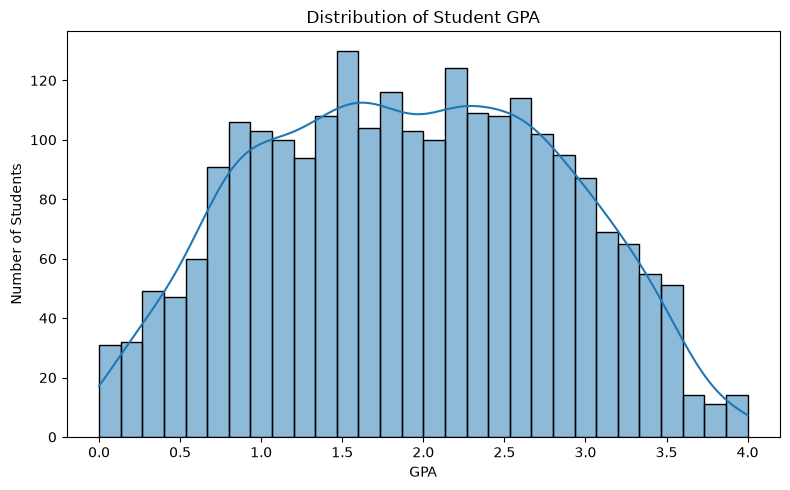

In [5]:
plot.figure(figsize=(8, 5))
seaborn.histplot(y, bins=30, kde=True)

plot.title("Distribution of Student GPA")
plot.xlabel("GPA")
plot.ylabel("Number of Students")
plot.tight_layout()
plot.show()


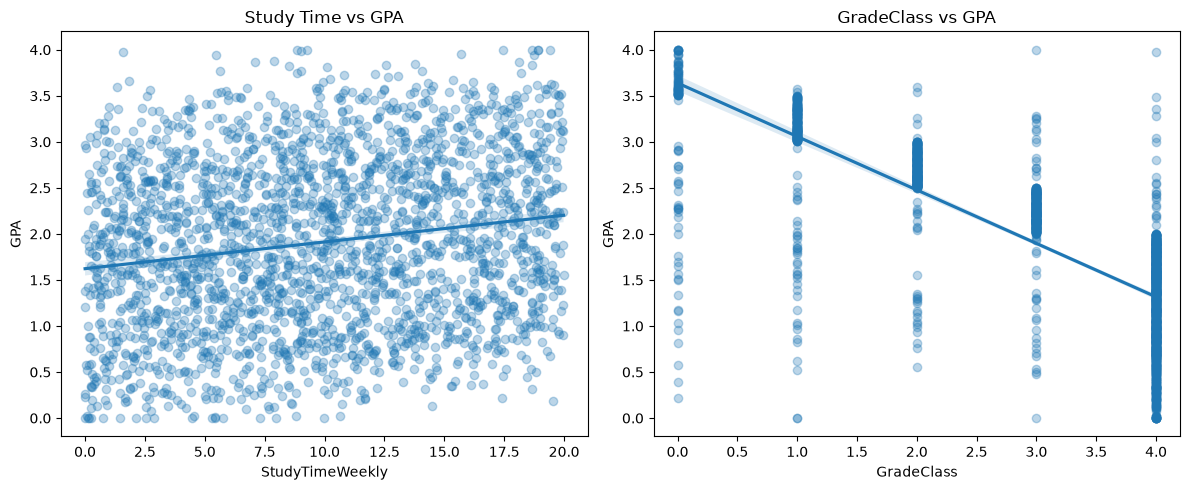

In [9]:
fig, axes = plot.subplots(1, 2, figsize=(12, 5))

seaborn.regplot(
    data=df, x="StudyTimeWeekly", y="GPA",
    scatter_kws={"alpha": 0.3}, ax=axes[0]
)
axes[0].set_title("Study Time vs GPA")

seaborn.regplot(
    data=df, x="GradeClass", y="GPA",
    scatter_kws={"alpha": 0.3}, ax=axes[1]
)
axes[1].set_title("GradeClass vs GPA")

plot.tight_layout()
plot.show()

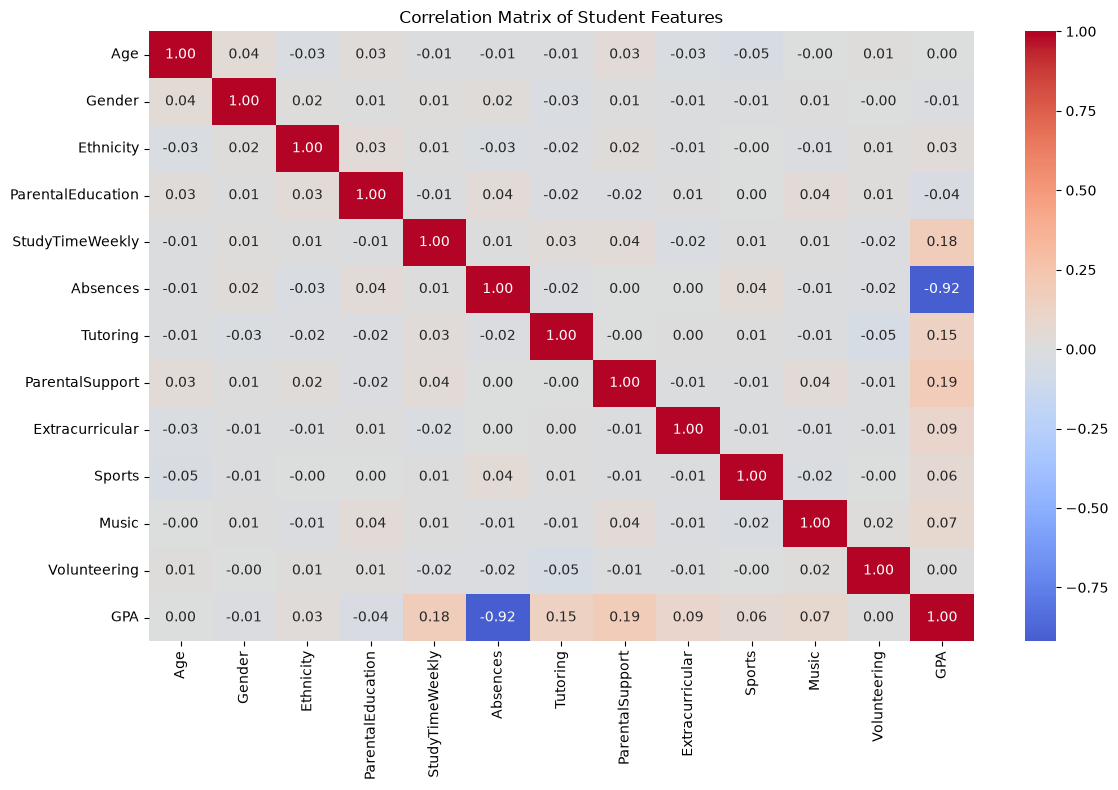

In [6]:
plot.figure(figsize=(12, 8))

seaborn.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plot.title("Correlation Matrix of Student Features")
plot.tight_layout()
plot.show()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 1913
Testing samples: 479


In [8]:
categorical_features = [
    "Gender", "Ethnicity",
    "ParentalEducation", "ParentalSupport"
]

numeric_features = [
    col for col in X.columns
    if col not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("numeric", StandardScaler(), numeric_features)
    ]
)

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import time

# Create the OLS pipeline
ols_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Train and measure execution time
start_time = time.perf_counter()
ols_model.fit(X_train, y_train)
ols_training_time = time.perf_counter() - start_time

# Generate predictions
y_train_pred = ols_model.predict(X_train)
y_test_pred = ols_model.predict(X_test)

# Evaluate both sets
def evaluate_model(y_true, y_pred, dataset_name):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "Dataset": dataset_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred)
    }

results = pd.DataFrame([
    evaluate_model(y_train, y_train_pred, "Training"),
    evaluate_model(y_test, y_test_pred, "Testing")
])

display(results)
print(f"OLS training time: {ols_training_time:.6f} seconds")

,Dataset,MAE,MSE,RMSE,R2
0,Training,0.159105,0.038421,0.196013,0.954238
1,Testing,0.155056,0.038537,0.196308,0.953398


OLS training time: 0.095767 seconds


In [10]:

from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
import time

models = {
    "Ridge": (
        Ridge(),
        {"model__alpha": [0.001, 0.01, 0.1, 1, 10, 100]}
    ),
    "Lasso": (
        Lasso(max_iter=10000),
        {"model__alpha": [0.0001, 0.001, 0.01, 0.1, 1]}
    )
}

tuned_models = {}
tuning_results = []

for name, (estimator, param_grid) in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    search = GridSearchCV(
        pipeline,
        param_grid,
        cv=5,
        scoring="neg_mean_squared_error",
        n_jobs=-1
    )

    start = time.perf_counter()
    search.fit(X_train, y_train)
    elapsed = time.perf_counter() - start

    tuned_models[name] = search.best_estimator_

    y_train_pred = search.best_estimator_.predict(X_train)
    y_test_pred = search.best_estimator_.predict(X_test)

    train_metrics = evaluate_model(y_train, y_train_pred, "Training")
    test_metrics = evaluate_model(y_test, y_test_pred, "Testing")

    tuning_results.append({
        "Model": name,
        "Best Alpha": search.best_params_["model__alpha"],
        "Best CV RMSE": np.sqrt(-search.best_score_),
        "Train MAE": train_metrics["MAE"],
        "Test MAE": test_metrics["MAE"],
        "Train RMSE": train_metrics["RMSE"],
        "Test RMSE": test_metrics["RMSE"],
        "Train R2": train_metrics["R2"],
        "Test R2": test_metrics["R2"],
        "Tuning Time (s)": elapsed
    })

tuning_df = pd.DataFrame(tuning_results)
display(tuning_df.round(5))


,Model,Best Alpha,Best CV RMSE,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2,Tuning Time (s)
0,Ridge,1.000,0.19827,0.15911,0.15511,0.19602,0.19640,0.95424,0.95336,12.42956
1,Lasso,0.001,0.19808,0.15920,0.15552,0.19618,0.19719,0.95416,0.95298,0.25546


In [11]:

def get_coefficients(pipeline):
    prep = pipeline.named_steps["preprocessor"]
    model = pipeline.named_steps["model"]

    feature_names = prep.get_feature_names_out()

    return pd.Series(
        model.coef_,
        index=feature_names
    )

coef_comparison = pd.DataFrame({
    "OLS": get_coefficients(ols_model),
    "Ridge": get_coefficients(tuned_models["Ridge"]),
    "Lasso": get_coefficients(tuned_models["Lasso"])
})

display(coef_comparison.round(4))


,OLS,Ridge,Lasso
categorical__Gender_0,-0.0052,-0.0052,-0.0061
categorical__Gender_1,0.0052,0.0052,0.0000
categorical__Ethnicity_0,-0.0079,-0.0079,-0.0064
categorical__Ethnicity_1,0.0019,0.0019,0.0000
categorical__Ethnicity_2,0.0016,0.0016,0.0000
categorical__Ethnicity_3,0.0044,0.0045,0.0000
categorical__ParentalEducation_0,-0.0014,-0.0014,-0.0000
categorical__ParentalEducation_1,-0.0036,-0.0035,-0.0000
categorical__ParentalEducation_2,0.0060,0.0060,0.0050
categorical__ParentalEducation_3,-0.0136,-0.0136,-0.0065


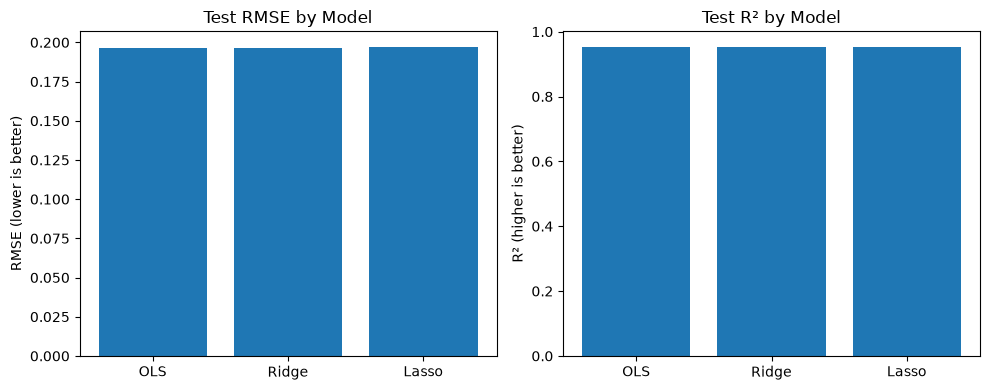

,Model,Test RMSE,Test R2
0,OLS,0.19631,0.95340
1,Ridge,0.19640,0.95336
2,Lasso,0.19719,0.95298


In [12]:


comparison = pd.DataFrame({
    "Model": ["OLS", "Ridge", "Lasso"],
    "Test RMSE": [
        np.sqrt(mean_squared_error(y_test, ols_model.predict(X_test))),
        np.sqrt(mean_squared_error(y_test, tuned_models["Ridge"].predict(X_test))),
        np.sqrt(mean_squared_error(y_test, tuned_models["Lasso"].predict(X_test)))
    ],
    "Test R2": [
        r2_score(y_test, ols_model.predict(X_test)),
        r2_score(y_test, tuned_models["Ridge"].predict(X_test)),
        r2_score(y_test, tuned_models["Lasso"].predict(X_test))
    ]
})

fig, axes = plot.subplots(1, 2, figsize=(10, 4))

axes[0].bar(comparison["Model"], comparison["Test RMSE"])
axes[0].set_title("Test RMSE by Model")
axes[0].set_ylabel("RMSE (lower is better)")

axes[1].bar(comparison["Model"], comparison["Test R2"])
axes[1].set_title("Test R² by Model")
axes[1].set_ylabel("R² (higher is better)")

plot.tight_layout()
plot.show()

display(comparison.round(5))
